# 01 · Describe motorcycle trade

**Question: how do reported trade values change, and which changes survive checks on units, coverage and seasonality?**

Bold sentences give the findings and decisions. The surrounding notes explain how to read them.

The data cover 2018–2025 and six reporting countries: Belgium (BE), Germany (DE), France (FR), the Netherlands (NL), Italy (IT) and Spain (ES).

- A reporter is the country submitting the figures. Imports enter that country; exports leave it. The partner is the country on the other side of the reported trade.
- One row combines a month, reporter, partner, motorcycle category and direction. It may include many transactions; it is not one motorcycle or a retail sale.
- CN8 is an eight-digit product code: `87113090` = >380–500 cm³; `87114000` = >500–800 cm³; `87115000` = >800 cm³. Engine capacity (cm³, or cc) describes engine size, not weight. These categories cover only part of motorcycle trade.

## 1. Start with one observation

I inspect Belgian imports from Japan, January 2024, CN8 87115000 (>800 cm³), before combining files. “Decoding” turns the source file's encoded structure into a table.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from moto_study.decoding import MEASURES, cell_at, decode_trade
from moto_study.io import (
    manifest,
    project_root,
    read_json,
    save_prepared,
    select_source,
    verify_sources,
)
from moto_study.plots import set_style
from moto_study.quality import assert_quality, prepare_trade, quality_checks, route_coverage

ROOT = project_root()
set_style()
snapshot = manifest(ROOT)
record = select_source(ROOT, reporter="BE", product="87115000", year=2024)
payload = read_json(ROOT, record)
small = decode_trade(payload, record)
one = small.loc[small.partner.eq("JP") & small.flow.eq("1") & small.month.eq("2024-01-01")]
assert len(one) == 1
coordinates = dict(
    freq="M", reporter="BE", partner="JP", product="87115000", flow="1", time="2024-01"
)
reconciliation = []
for indicator, column in MEASURES.items():
    raw_cell = cell_at(payload, {**coordinates, "indicators": indicator})
    assert np.isclose(raw_cell["value"], one[column].iloc[0])
    reconciliation.append(
        {
            "measure": column,
            "raw_value": raw_cell["value"],
            "decoded_value": one[column].iloc[0],
            "source_flag": raw_cell["status"] or "No flag supplied",
        }
    )
display(pd.DataFrame(reconciliation).set_index("measure"))

,raw_value,decoded_value,source_flag
measure,,,
value_eur,4928487.00,4928487.00,No flag supplied
mass_100kg,1284.09,1284.09,No flag supplied
supplementary_quantity,554.00,554.00,No flag supplied


**The three decoded values match the source. The mass conversion is essential: 1,284.09 units of 100 kg become 128,409 kg.**

- “No flag supplied” means the source adds no annotation. It does not certify the measurement's quality.
- EUR/kg divides reported trade value by net mass. Here it is EUR 38.38/kg. It is neither the price of one motorcycle nor a retail price; the mix of motorcycles can change it.
- The full combination of month, reporter, partner, product and direction identifies a row. Repeating that combination would double-count it. Adding an all-partners total to individual partners would also double-count trade.
- Supplementary quantity is an extra quantity field. I retain it without assuming one unit applies everywhere. [Source definitions](../docs/DATA_SOURCES.md).

I now follow this route—the same reporter, partner, category and direction—over 12 months.

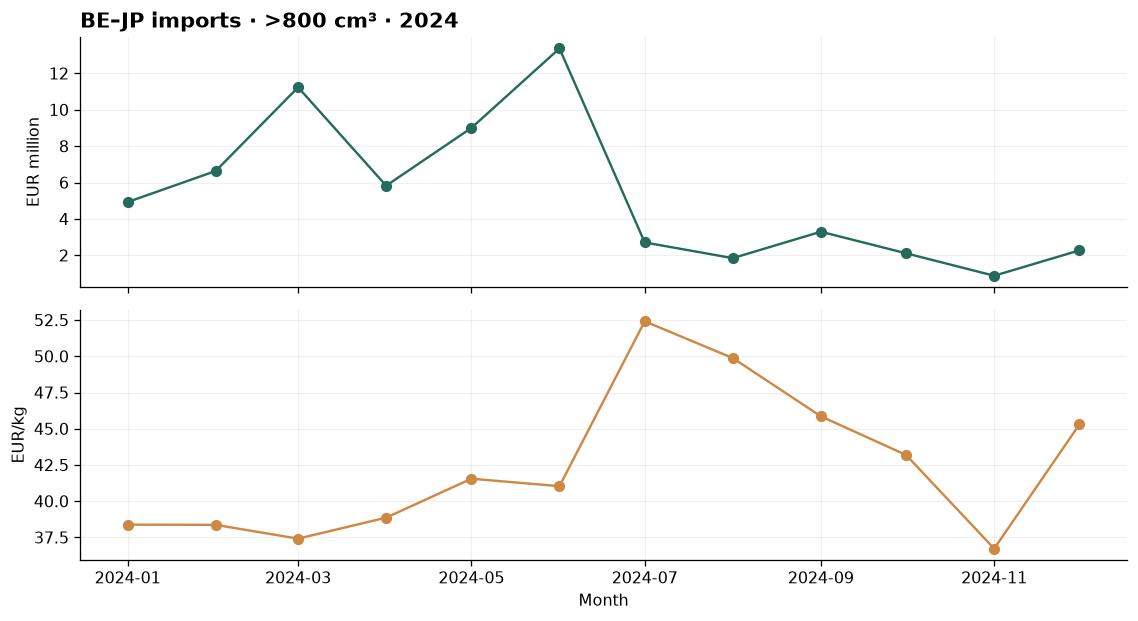

In [2]:
route = small.loc[small.partner.eq("JP") & small.flow.eq("1")].sort_values("month").copy()
route["net_mass_kg"] = route.mass_100kg * 100
route["unit_value_eur_per_kg"] = route.value_eur / route.net_mass_kg.where(route.net_mass_kg.gt(0))
assert route.month.tolist() == list(pd.date_range("2024-01-01", "2024-12-01", freq="MS"))
fig, axes = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
axes[0].plot(route.month, route.value_eur / 1e6, marker="o")
axes[0].set(title="BE–JP imports · >800 cm³ · 2024", ylabel="EUR million")
axes[1].plot(route.month, route.unit_value_eur_per_kg, marker="o", color="#cd8844")
axes[1].set(ylabel="EUR/kg", xlabel="Month")
fig.tight_layout()
plt.show()

**June has the highest trade value, but not the highest EUR/kg. I keep the peak and check its mass and seasonal context below.**

## 2. Check the full dataset

I check file fingerprints (“hashes”) to confirm the bundled files have not changed. This checks file integrity, not whether the reported trade is correct.

I then check row identifiers, scope, source flags and arithmetic. Overlapping totals are excluded; invalid measurements stop the analysis.

In [3]:
audit = verify_sources(ROOT)
raw = pd.concat(
    [decode_trade(read_json(ROOT, item), item) for item in snapshot["sources"]], ignore_index=True
)
trade, excluded, quarantine = prepare_trade(raw, snapshot["scope"])
assert len(raw) == len(trade) + len(excluded) + len(quarantine)
assert quarantine.empty, "Invalid measurements need a decision before analysis."
checks = quality_checks(trade, audit.source_id)
assert_quality(checks)
assert raw.groupby("product").product_label.nunique().le(1).all()
coverage = route_coverage(trade)
zero_mass = trade.net_mass_kg.eq(0)
flags = [name + "_status" for name in MEASURES.values()]
display(
    pd.Series(
        {
            "source files verified": len(audit),
            "quality checks passed": len(checks),
            "decoded rows": len(raw),
            "scope exclusions": len(excluded),
            "accepted rows": len(trade),
            "missing source measurements": int(trade[list(MEASURES.values())].isna().sum().sum()),
            "flagged measurements": int(trade[flags].ne("").sum().sum()),
            "zero-mass rows": int(zero_mass.sum()),
            "zero-mass rows from NL": int((zero_mass & trade.reporter.eq("NL")).sum()),
            "median internal route gaps": int(coverage.internal_gaps.median()),
        },
        name="Result",
    )
)
print(
    f"Zero-mass rows represent {100 * trade.loc[zero_mass, 'value_eur'].sum() / trade.value_eur.sum():.4f}% of recorded value."
)
save_prepared(ROOT, trade, checks)

source files verified             144
quality checks passed              10
decoded rows                   113403
scope exclusions                32751
accepted rows                   80652
missing source measurements         0
flagged measurements                0
zero-mass rows                   3281
zero-mass rows from NL           3256
median internal route gaps         19
Name: Result, dtype: int64

Zero-mass rows represent 0.0029% of recorded value.


- **80,652 rows remain after excluding 32,751 overlapping totals and special-partner rows.** Alternative country codes are standardized before checking duplicates. Excluded special codes are listed in the source notes; these choices affect coverage.
- **No source measurement is missing or flagged, but 3,281 rows have zero mass, mostly from NL. I keep their EUR values and leave EUR/kg undefined.** Dividing by zero would give a meaningless ratio.
- **The median route has 19 internal gaps. I do not turn absent months into zeros.** “Median” means the middle count across routes; internal gaps fall between a route's first and last record. A missing record does not tell us whether trade was zero.

Stable product labels alone do not prove unchanged classifications. Source revisions and country-code coverage remain limits.

## 3. Inspect distributions

Each histogram bar counts records in a value range. A few large flows can hide smaller ones. The log scale compresses large amounts: equal distances represent proportional changes, not equal EUR amounts.

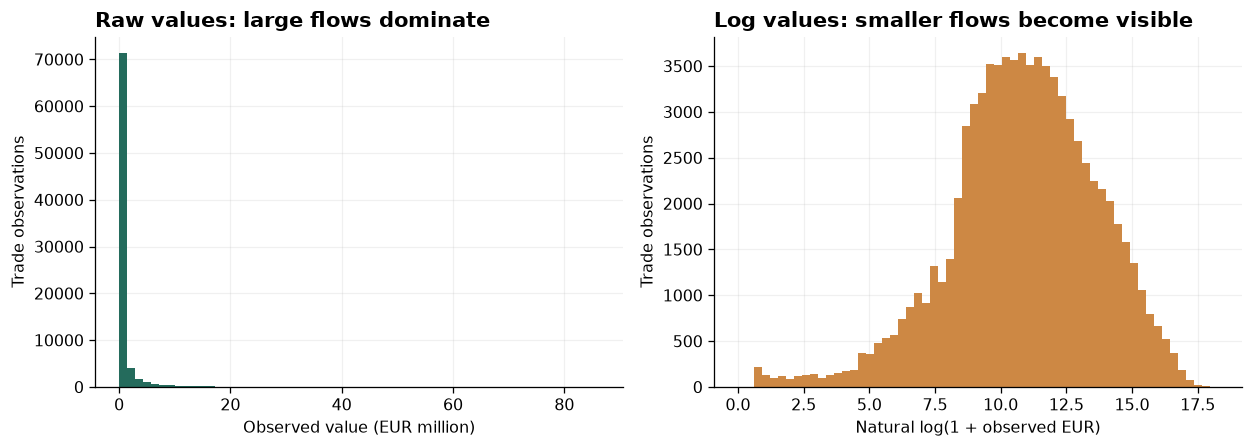

Median: EUR 56,700; 99th percentile: EUR 12.63m.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(trade.value_eur / 1e6, bins=60)
axes[0].set(
    title="Raw values: large flows dominate",
    xlabel="Observed value (EUR million)",
    ylabel="Trade observations",
)
axes[1].hist(np.log1p(trade.value_eur), bins=60, color="#cd8844")
axes[1].set(
    title="Log values: smaller flows become visible",
    xlabel="Natural log(1 + observed EUR)",
    ylabel="Trade observations",
)
fig.tight_layout()
plt.show()
print(
    f"Median: EUR {trade.value_eur.median():,.0f}; 99th percentile: EUR {trade.value_eur.quantile(0.99) / 1e6:.2f}m."
)

**Half the monthly records are at or below EUR 56,700, while the 99th percentile reaches EUR 12.63m. I will compare raw and log models, then measure errors in EUR.**

The 99th percentile means about 99% of records are at or below that value. This wide range explains the log view; it does not make the largest observations errors.

## 4. Separate growth from coverage

Belgian import partners fall from 28 in 2024 to 21 in 2025. A changing set of reported routes can affect growth. I compare all observed values with a fixed group (“cohort”) of routes reported every month in both years.

In [5]:
be = trade.loc[trade.reporter.eq("BE") & trade.flow.eq("1")].copy()
recent = be.loc[be.month.between("2024-01-01", "2025-12-01")]
counts = recent.groupby(["partner", "product"]).month.nunique()
complete_routes = counts.loc[counts.eq(24)].reset_index()[["partner", "product"]]
balanced = recent.merge(complete_routes, on=["partner", "product"], validate="many_to_one")
comparison = pd.DataFrame(
    {
        "All observed routes": recent.groupby(recent.month.dt.year).value_eur.sum(),
        "Same routes in all 24 months": balanced.groupby(balanced.month.dt.year).value_eur.sum(),
    }
).T
comparison["growth_percent"] = (comparison[2025] / comparison[2024] - 1) * 100
comparison[[2024, 2025]] /= 1e6
display(comparison.rename(columns={2024: "2024_EUR_m", 2025: "2025_EUR_m"}).round(2))
print(
    f"{len(complete_routes)} complete routes; {100 * comparison.loc['Same routes in all 24 months', 2025] / comparison.loc['All observed routes', 2025]:.2f}% of 2025 value."
)

month,2024_EUR_m,2025_EUR_m,growth_percent
All observed routes,601.20,617.28,2.68
Same routes in all 24 months,531.63,583.49,9.75


17 complete routes; 94.53% of 2025 value.


**Import value grows 2.68% overall, versus 9.75% for continuously reported routes. Coverage changes the interpretation, so I report both.**

The fixed group makes the comparison more consistent, but favors persistent routes. Its growth is not a correction that replaces the overall figure.

I then split Belgian import value by engine category and partner to see what drives the total.

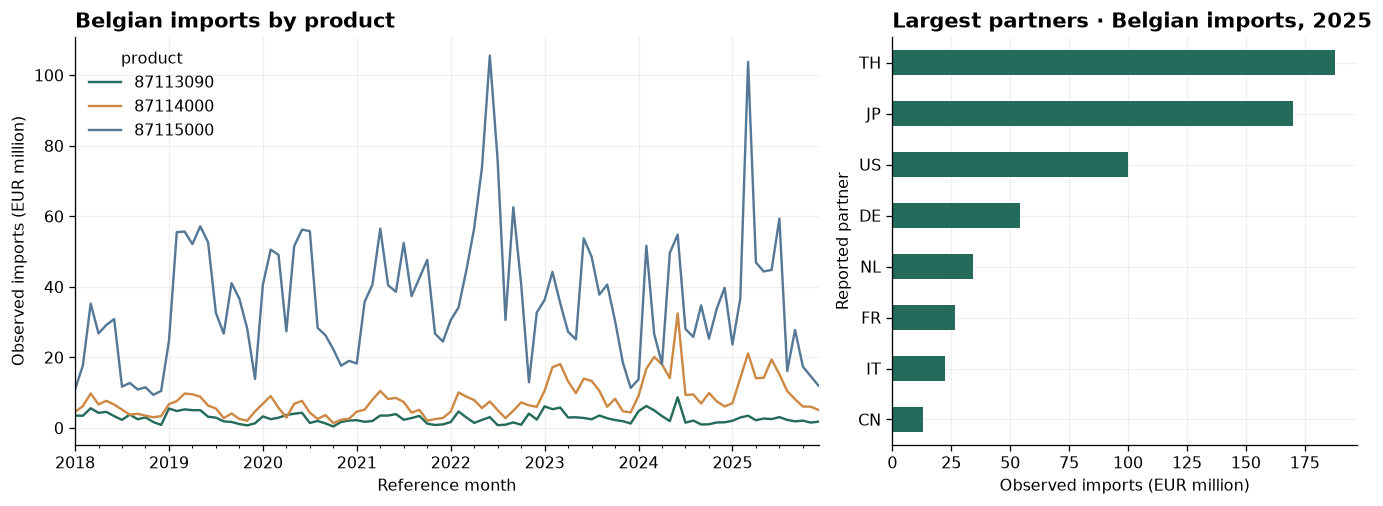

In [6]:
trend = be.groupby(["month", "product"]).value_eur.sum(min_count=1).unstack("product")
partners = (
    be.loc[be.month.dt.year.eq(2025)]
    .groupby("partner")
    .value_eur.sum()
    .sort_values(ascending=False)
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
(trend / 1e6).plot(ax=axes[0])
axes[0].set(
    title="Belgian imports by product",
    xlabel="Reference month",
    ylabel="Observed imports (EUR million)",
)
(partners.head(8).sort_values() / 1e6).plot.barh(ax=axes[1])
axes[1].set(
    title="Largest partners · Belgian imports, 2025",
    xlabel="Observed imports (EUR million)",
    ylabel="Reported partner",
)
fig.tight_layout()
plt.show()

**The >800 cm³ category dominates. Thailand and Japan account for 57.98% of observed Belgian import value in 2025. The total therefore depends heavily on a few partners.**

The chart uses country codes: TH = Thailand, JP = Japan, US = United States and CN = China. A reported partner does not necessarily establish where a motorcycle was manufactured.

## 5. Test the seasonal expectation

Hypothesis: imports rise in spring and early summer as dealers prepare for the riding season. Trade data can test the timing pattern, but do not directly measure dealer stocks or retail demand.

- Compare the average month in March–June with winter (January, February and December of the same year), for 2018–2023. Using averages avoids comparing four months' totals with three.
- Set each country-year's monthly average to 100. An index of 130 means 30% above that year's average, not 30% annual growth. Give each country-year equal weight so larger countries do not dominate.
- Compare value and mass. Repeat on routes observed all year to check whether changing coverage creates the pattern.

A country-year is one country in one year: six countries × six years = 36. The table takes each country's middle yearly ratio. A ratio of 1.69 means the March–June monthly average is 69% higher than winter.

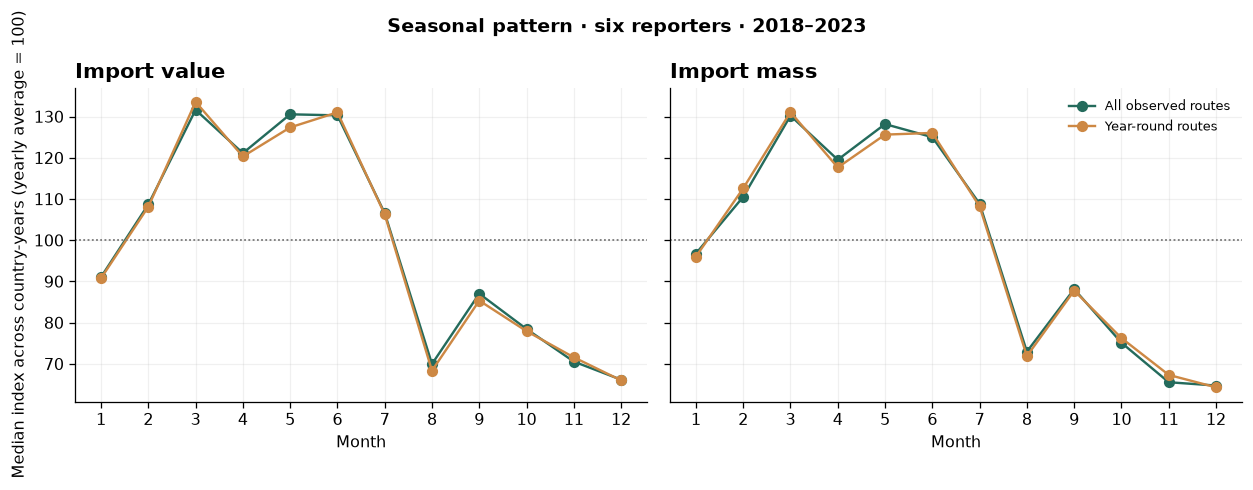

In [7]:
imports = trade.loc[trade.flow.eq("1") & trade.month.dt.year.le(2023)].copy()
# Do not let a partial sum hide missing or flagged measurements.
assert imports[["value_eur", "net_mass_kg"]].notna().all().all()
assert imports[["value_eur_status", "mass_100kg_status"]].eq("").all().all()
imports["year"] = imports.month.dt.year
route_year = ["reporter", "partner", "product", "year"]
complete = imports.groupby(route_year).month.transform("nunique").eq(12)
profiles = []
for scope, rows in [("All observed routes", imports), ("Year-round routes", imports.loc[complete])]:
    monthly_imports = (
        rows.groupby(["reporter", "year", "month"])[["value_eur", "net_mass_kg"]]
        .sum(min_count=1)
        .reset_index()
    )
    # Require complete yearly calendars before calculating seasonal indices.
    assert monthly_imports.groupby(["reporter", "year"]).month.nunique().eq(12).all()
    assert np.isfinite(monthly_imports[["value_eur", "net_mass_kg"]]).all().all()
    annual_average = monthly_imports.groupby(["reporter", "year"])[
        ["value_eur", "net_mass_kg"]
    ].transform("mean")
    assert annual_average.gt(0).all().all()
    monthly_imports[["value_index", "mass_index"]] = (
        monthly_imports[["value_eur", "net_mass_kg"]] / annual_average * 100
    ).to_numpy()
    monthly_imports["calendar_month"] = monthly_imports.month.dt.month
    monthly_imports["scope"] = scope
    profiles.append(monthly_imports)
seasonal = pd.concat(profiles, ignore_index=True)
assert np.allclose(
    seasonal.groupby(["scope", "reporter", "year"])[["value_index", "mass_index"]].mean(), 100
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for scope, rows in seasonal.groupby("scope", sort=False):
    profile = rows.groupby("calendar_month")[["value_index", "mass_index"]].median()
    for ax, column, title in zip(
        axes, ["value_index", "mass_index"], ["Import value", "Import mass"]
    ):
        ax.plot(profile.index, profile[column], marker="o", label=scope)
        ax.set(title=title, xlabel="Month", xticks=range(1, 13))
        ax.axhline(100, color="grey", linestyle=":", linewidth=1)
axes[0].set_ylabel("Median index across country-years (yearly average = 100)")
axes[1].legend(fontsize=8)
fig.suptitle("Seasonal pattern · six reporters · 2018–2023", fontweight="bold")
fig.tight_layout()
plt.show()

In [8]:
spring = seasonal.loc[seasonal.calendar_month.between(3, 6)]
winter = seasonal.loc[seasonal.calendar_month.isin([12, 1, 2])]
keys = ["scope", "reporter", "year"]
ratios = (
    (spring.groupby(keys).value_eur.mean() / winter.groupby(keys).value_eur.mean())
    .rename("ratio")
    .reset_index()
)
summary = ratios.groupby(["reporter", "scope"]).ratio.median().unstack("scope")
all_routes = ratios.loc[ratios.scope.eq("All observed routes")]
summary["years_above_winter"] = all_routes.groupby("reporter").ratio.apply(
    lambda x: int(x.gt(1).sum())
)
display(summary.round(2))
without_2020 = all_routes.loc[all_routes.year.ne(2020)]
print(
    f"Above winter: {all_routes.ratio.gt(1).sum()}/{len(all_routes)} country-years; excluding 2020: {without_2020.ratio.gt(1).sum()}/{len(without_2020)}."
)

scope,All observed routes,Year-round routes,years_above_winter
reporter,,,
BE,1.69,1.67,6
DE,1.47,1.46,6
ES,1.23,1.22,5
FR,1.46,1.45,5
IT,1.36,1.33,5
NL,1.30,1.30,6


Above winter: 33/36 country-years; excluding 2020: 30/30.


**March–June exceeds winter in 33/36 country-years, or 30/30 when 2020 is left out (covid year). Value and mass show similar patterns, including on year-round routes.**

**This supports testing seasonal forecasts. It does not establish that weather or retail sales caused the pattern.** Seasonality means a pattern that repeats around the same calendar months.

### Revisit the June peak

I compare the original Belgian–Japanese route with June a year earlier. Comparing the same month helps separate the usual seasonal pattern from an unusually large change.

In [9]:
june = trade.loc[
    trade.reporter.eq("BE")
    & trade.partner.eq("JP")
    & trade["product"].eq("87115000")
    & trade.flow.eq("1")
    & trade.month.isin(pd.to_datetime(["2023-06-01", "2024-06-01"]))
].set_index("month")[["value_eur", "net_mass_kg", "unit_value_eur_per_kg"]]
assert len(june) == 2 and june.gt(0).all().all()
factors = june.loc["2024-06-01"] / june.loc["2023-06-01"]
assert np.isclose(factors.value_eur, factors.net_mass_kg * factors.unit_value_eur_per_kg)
june_check = june.T.rename(columns=lambda x: x.strftime("%Y-%m"))
june_check["change_percent"] = (factors - 1) * 100
display(june_check.round(2))

month,2023-06,2024-06,change_percent
value_eur,3532802.00,13370050.00,278.45
net_mass_kg,80432.00,325813.00,305.08
unit_value_eur_per_kg,43.92,41.04,-6.57


**Value rises 278.5%, mass rises 305.1% and EUR/kg falls 6.6%. The value jump reflects more traded mass, rather than a higher value per kg.**

This follows from value = mass × EUR/kg. It explains the arithmetic, not why shipments changed. More mass does not necessarily mean the same proportional increase in the number of motorcycles.

## Conclusion

**I retain the June peak: a large value alone is not enough to call it an error. Coverage, partner concentration and seasonality guide the next checks.** Next, I [compare monthly forecasts](02_monthly_forecasts.ipynb).